# Financial News Sentiment: TF-IDF + Logistic Regression vs FinBERT

## Introduction
This notebook asks one question: **is a pretrained financial transformer worth its cost compared with a simple TF-IDF baseline, and does it still work on Indian headlines?**

1. **TF-IDF + Logistic Regression**: learns a weight for each word and word pair. Fast, small, needs labelled data. This is the baseline.
2. **FinBERT (zero-shot)**: `ProsusAI/finbert`, already trained on financial text, used with no training here.
3. **FinBERT (fine-tuned)**: FinBERT trained further on my training split (bonus).

**Metric:** macro F1. The classes are imbalanced (neutral ≈ 59%, negative ≈ 12%), so accuracy would hide poor performance on negatives.
**Test sets:** a stratified 20% hold-out (970 sentences) and 10 hand-labelled Indian headlines.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report,confusion_matrix,
                             f1_score)
from transformers import (pipeline,AutoTokenizer,
                          AutoModelForSequenceClassification,
                          Trainer,TrainingArguments)
from datasets import Dataset

## Data
**Source:** Financial PhraseBank (Malo et al., 2014), 4,846 English financial news sentences labelled negative / neutral / positive. Link: <add>.
**License:** CC BY-NC-SA 3.0 (non-commercial). Confirm on the page you downloaded it from.

| Label | Sentences | Share |
|---|---|---|
| neutral | 2,879 | 59.4% |
| positive | 1,363 | 28.1% |
| negative | 604 | 12.5% |

**Caveat:** mostly European company news. Indian terms (crore, repo rate, Q2) are rare, which is why the Indian headlines test matters.

In [2]:
df = pd.read_csv("/content/data.csv",encoding="latin-1",header=None)
df.columns = ['sentiment','text']
df.head()

,sentiment,text
0,neutral,"According to Gran , the company has no plans t..."
1,neutral,Technopolis plans to develop in stages an area...
2,negative,The international electronic industry company ...
3,positive,With the new production plant the company woul...
4,positive,According to the company 's updated strategy f...


### Class balance
Neutral is about 59% and negative about 12%. A model that always says "neutral" would already be right 59% of the time, so I use **macro F1** and `class_weight="balanced"`.

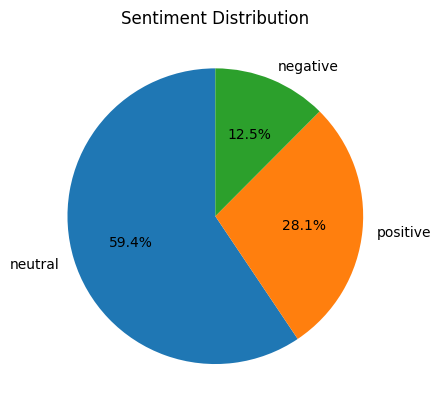

In [3]:
df['sentiment'].value_counts().plot(
    kind='pie',
    autopct="%1.1f%%",
    startangle=90
)
plt.title('Sentiment Distribution')
plt.ylabel("")
plt.show()


### Encoding labels
negative = 0, neutral = 1, positive = 2. FinBERT returns label *names*, so I map them with the same `target_map`.

In [4]:
target_map = {"neutral":1,"negative":0,"positive":2}
df['sentiment'] = df['sentiment'].map(target_map)
df.head()

,sentiment,text
0,1,"According to Gran , the company has no plans t..."
1,1,Technopolis plans to develop in stages an area...
2,0,The international electronic industry company ...
3,2,With the new production plant the company woul...
4,2,According to the company 's updated strategy f...


### Train / test split
80/20, `stratify=y`, `random_state=42`: 3,876 train and 970 test sentences. Stratifying keeps class shares equal in both parts, and the test set is only used for evaluation.

In [5]:
y = df['sentiment']
X = df['text']
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)
print("Y-train Distribution: ")
display(pd.DataFrame(y_train).value_counts(normalize=True))
print("Y-test Distribution: ")
display(pd.DataFrame(y_test).value_counts(normalize=True))

Y-train Distribution: 


,proportion
sentiment,
1,0.594169
2,0.281218
0,0.124613


Y-test Distribution: 


,proportion
sentiment,
1,0.593814
2,0.281443
0,0.124742


## Classical baseline: TF-IDF + Logistic Regression
- **`ngram_range=(1, 2)`**: single words and word pairs ("net profit", "up from").
- **`min_df=2`**: drops words seen in only one sentence.
- **`class_weight="balanced"`**: mistakes on the rare negative class cost more.

**Why `stop_words=None`:** the default English stop-word list removes "not" and "no", and negations flip sentiment. It also contains "up", "down" and "off", which are among the strongest features here (see the top-words cell).

In [6]:
baseline = Pipeline([
    ("tfidf",TfidfVectorizer(ngram_range=(1,2),min_df=2,stop_words=None)),
    ("clf",LogisticRegression(max_iter=1000,class_weight='balanced'))
])
baseline.fit(x_train,y_train)
y_pred=baseline.predict(x_test)

### Baseline evaluation
Classification report (precision, recall, F1 per class), confusion matrix (rows = real, columns = predicted), and macro F1.

              precision    recall  f1-score   support

           0       0.62      0.69      0.65       121
           1       0.83      0.82      0.82       576
           2       0.65      0.65      0.65       273

    accuracy                           0.75       970
   macro avg       0.70      0.72      0.71       970
weighted avg       0.76      0.75      0.75       970



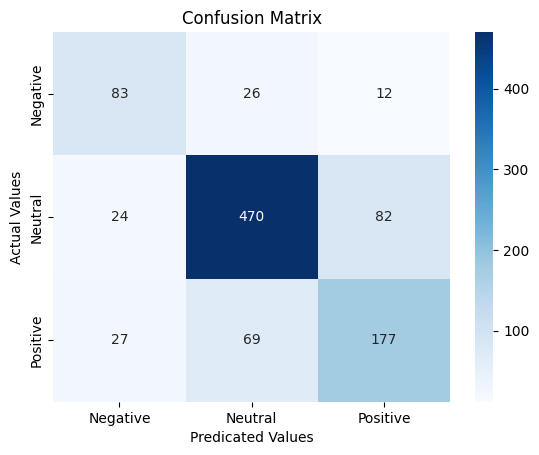

F1-Score:0.7085181414078924


In [7]:
print(classification_report(y_test,y_pred))
cm = confusion_matrix(y_test,y_pred)

labels=['Negative','Neutral','Positive']
sns.heatmap(cm,cmap="Blues",fmt="d",annot=True,
            xticklabels=labels,yticklabels=labels)
plt.xlabel("Predicated Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix")
plt.show()
print(f"F1-Score:{f1_score(y_test,y_pred,average='macro')}")

**Result:** macro F1 = **0.709**, accuracy 0.75. Neutral is easiest (F1 0.82), and negative and positive are both 0.65. Negative has precision 0.62 and recall 0.69: `balanced` finds more negatives at the cost of false alarms.


### What did the baseline learn?
`coef_` has one row of word weights per class (0 = negative, 2 = positive). A large weight pushes the prediction towards that class.

In [8]:
feature_names = baseline.named_steps['tfidf'].get_feature_names_out()
coefficients = baseline.named_steps['clf'].coef_ # since this is multiclass we get 1 col for each class

pos_df = pd.DataFrame({
    'word': feature_names,
    'coefficient': coefficients[2]
})

neg_df = pd.DataFrame({
    'word': feature_names,
    'coefficient': coefficients[0]
})

top_positives = pos_df.sort_values(by='coefficient',ascending=False).head(10)
top_negatives = neg_df.sort_values(by='coefficient',ascending=False).head(10)

print("--- Top 10 Most Positive Words ---")
print(top_positives)

print("\n--- Top 10 Most Negative Words ---")
print(top_negatives)

--- Top 10 Most Positive Words ---
            word  coefficient
5659    increase     2.882212
5667   increased     2.626662
11870         up     2.480123
9332        rose     2.417907
11874    up from     2.201262
4926        grew     2.014558
9824      signed     1.884760
9336     rose to     1.841346
8046         our     1.747851
6377     leading     1.729409

--- Top 10 Most Negative Words ---
            word  coefficient
3489        down     4.072887
3229   decreased     3.649134
4240        fell     2.854065
6598       lower     1.996060
10069      staff     1.989314
3494   down from     1.847895
9241      result     1.819857
7736         off     1.694500
6358         lay     1.674588
3515     dropped     1.630783


**The most negative words were** *down, decreased, fell, lower, staff, down from, result, off, lay, dropped*. **This matches my intuition** for *down, decreased, fell, lower, dropped* (numbers going the wrong way). *staff, lay, off* are pieces of "lay off staff" (job cuts), and *result* is probably from "operating result decreased".

**The most positive words were** *increase, increased, up, rose, up from, grew, signed, rose to, our, leading*. This matches for *increase, up, rose, grew* (rising numbers), *signed* (deals) and *leading*. ***our* does not match my intuition**: a pronoun has no sentiment. My guess is that it comes from company statements ("our profit grew"). <check in x_train>

*up, down, off* and *our* are all in sklearn's default stop-word list, which confirms the `stop_words=None` choice.

### Indian headlines: hand-labelled test set
10 recent Indian business headlines (4 positive, 3 negative, 3 neutral), labelled by me before running any model.
**Caveats:** only 10 examples (one error = 10 points of accuracy), and labels are a judgement ("crude oil surges 85%" is negative from a macro view).

In [9]:
latest_news = pd.Series([
    "Tata Motors CV swings to 1,257 crore profit in Q2; revenue rises 36%",
    "Swiggy slumps 15% to new low as Q2 results fall below expectations",
    "The Conference Board Leading Economic Index for the US remained flat in September",
    "JSW Steel Q2 net profit jumps over 3x to Rs 5,279 crore on higher sales",
    "IT companies add over 16,000 employees in H1, but overall client demand remains weak",
    "RBI keeps repo rate unchanged at 6.5% as monetary policy committee reviews inflation trends",
    "Jio Platforms IPO rides massive institutional demand to 22x subscription on day two",
    "Crude oil prices surge 85% over the year, posing a major threat to global economic recovery",
    "Company management announces routine quarterly earnings conference call scheduled for next Tuesday",
    "Infosys raises full-year revenue growth guidance following robust multi-deal wins"
])
sentiments = pd.Series([
    "positive",
    "negative",
    "neutral",
    "positive",
    "negative",
    "neutral",
    "positive",
    "negative",
    "neutral",
    "positive"
]).map(target_map)

In [10]:
new_pred = baseline.predict(latest_news)
print(classification_report(sentiments,new_pred))
print(f"F1-Score: {f1_score(sentiments,new_pred,average='macro')}")

              precision    recall  f1-score   support

           0       1.00      0.67      0.80         3
           1       0.40      0.67      0.50         3
           2       0.33      0.25      0.29         4

    accuracy                           0.50        10
   macro avg       0.58      0.53      0.53        10
weighted avg       0.55      0.50      0.50        10

F1-Score: 0.5285714285714286


**Result:** macro F1 = **0.529** (accuracy 0.50), 18.0 points below the 0.709 on the main test set. Only 1 of 4 positive headlines was found (recall 0.25). Likely reason: words like "crore", "Q2" and "repo" were never seen in training, and TF-IDF can only use words it has seen.

## Transformer (HuggingFace): FinBERT, zero-shot
`ProsusAI/finbert` is BERT-base (about 110M parameters) further trained on financial text and fine-tuned on Financial PhraseBank. "Zero-shot" means I do no training. The `pipeline` hides tokenising, the model run and the label/confidence output.


In [11]:
bert = pipeline("sentiment-analysis", model="ProsusAI/finbert")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [12]:
result = bert(x_test.to_list())
result[:5]

[{'label': 'neutral', 'score': 0.8636738657951355},
 {'label': 'neutral', 'score': 0.9528343677520752},
 {'label': 'neutral', 'score': 0.6838157176971436},
 {'label': 'positive', 'score': 0.9449496269226074},
 {'label': 'negative', 'score': 0.9762623906135559}]

### Running FinBERT on the test set
Batches of 16 with `truncation=True` (cuts anything over 512 tokens). Each output is a label plus a confidence.

              precision    recall  f1-score   support

           0       0.76      0.97      0.85       121
           1       0.95      0.84      0.89       576
           2       0.79      0.90      0.84       273

    accuracy                           0.87       970
   macro avg       0.84      0.90      0.86       970
weighted avg       0.88      0.87      0.87       970



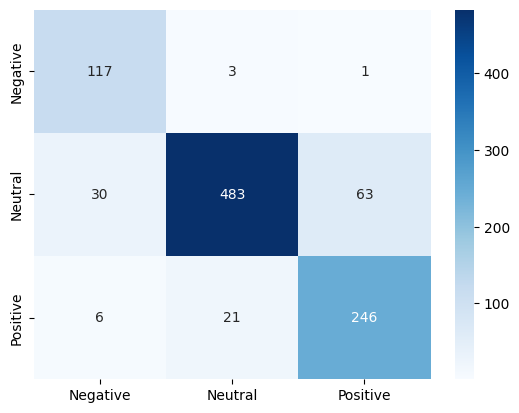

F1-score: 0.8632973879059578


In [13]:
y_pred_bert = [res['label'] for res in result]
y_pred_bert = pd.Series(y_pred_bert).map(target_map)

print(classification_report(y_test,y_pred_bert))
cm_bert = confusion_matrix(y_test,y_pred_bert)
sns.heatmap(cm_bert,cmap='Blues',annot=True,fmt='d',
            xticklabels=labels,yticklabels=labels)
plt.show()
print(f"F1-score: {f1_score(y_test,y_pred_bert,average='macro')}")

### FinBERT evaluation
Labels are mapped back to integers by name, then the same report, matrix and macro F1 as the baseline.

**Result:** macro F1 = **0.863**, accuracy 0.87, which is **15.5 points above the baseline**. Class F1 (baseline → FinBERT): negative 0.65 → 0.85, neutral 0.82 → 0.89, positive 0.65 → 0.84. Negative recall is 0.97 but precision 0.76 (it over-flags negatives). Neutral precision is 0.95 but recall 0.84. Part of this gap may be leakage (see caution above).

### FinBERT on the Indian headlines
Same 10 headlines, no retraining.

In [14]:
result_new = bert(latest_news.to_list())

              precision    recall  f1-score   support

           0       0.67      0.67      0.67         3
           1       1.00      0.67      0.80         3
           2       0.80      1.00      0.89         4

    accuracy                           0.80        10
   macro avg       0.82      0.78      0.79        10
weighted avg       0.82      0.80      0.80        10



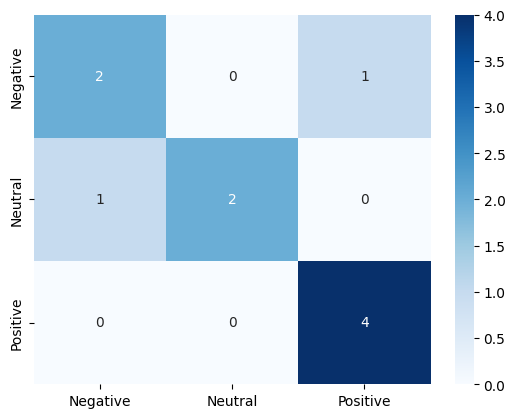

F1-score: 0.7851851851851852


In [15]:
new_pred_bert =pd.Series([res['label'] for res in result_new]).map(target_map)

print(classification_report(sentiments,new_pred_bert))
cm_bert = confusion_matrix(sentiments,new_pred_bert)
sns.heatmap(cm_bert,cmap='Blues',annot=True,fmt='d',
            xticklabels=labels,yticklabels=labels)
plt.show()
print(f"F1-score: {f1_score(sentiments,new_pred_bert,average='macro')}")

**Result:** macro F1 = **0.785** (accuracy 0.80), 25.7 points above the baseline. All 4 positives found, with one false positive. FinBERT drops 7.8 points from the main test set versus 18.0 for the baseline, so financial pretraining transfers better to Indian text. Only 10 headlines, so treat this as a direction.

## Fine-tuning FinBERT
**Question:** does training FinBERT on my own training split beat zero-shot? Steps: tokenise, wrap as `Dataset`, train with `Trainer`, evaluate the same way. This needs labelled data and compute (about 18 minutes here), which is the cost zero-shot avoids.

### Tokenizer
The tokenizer splits text into sub-word pieces and maps them to numbers. It must be the model's own, because the model only knows its own vocabulary.


In [16]:
model_name="ProsusAI/finbert"

tokenizer = AutoTokenizer.from_pretrained(model_name)

### Preparing the datasets
Each example gets `input_ids` (token numbers), `token_type_ids` and `attention_mask` (1 = real token, 0 = padding). `padding="max_length"` pads every sentence to 512 tokens, which wastes compute and slowed training.


In [17]:
ft_train = Dataset.from_dict({"text": x_train.tolist(),'label':y_train.to_list()})
ft_test = Dataset.from_dict({"text": x_test.tolist(),'label':y_test.to_list()})
def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True)

ft_train =ft_train.map(tokenize_function,batched=True)
ft_test = ft_test.map(tokenize_function,batched=True)
ft_train


Map:   0%|          | 0/3876 [00:00<?, ? examples/s]

Map:   0%|          | 0/970 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 3876
})

### Training
`num_labels=3` adds a 3-class head. Defaults: 3 epochs, learning rate 5e-5, batch size 8. FinBERT's own head uses a different label order from mine, and I set `id2label` only after training. There is no evaluation during training, so no validation curve or early stopping.

In [18]:
model = AutoModelForSequenceClassification.from_pretrained(model_name,num_labels=3)
train_args = TrainingArguments("test_trainer")

trainer=Trainer(
    model = model,args=train_args,train_dataset=ft_train,eval_dataset=ft_test
)
trainer.train()



Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Step,Training Loss
500,0.500749
1000,0.219643


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1455, training_loss=0.27707103978317627, metrics={'train_runtime': 1085.6733, 'train_samples_per_second': 10.71, 'train_steps_per_second': 1.34, 'total_flos': 3059482821341184.0, 'train_loss': 0.27707103978317627, 'epoch': 3.0})

**Training result:** 1,455 steps (3 epochs × 485) in about 1,064 s (~18 min), average training loss 0.277. This says nothing yet about new sentences.

### Fine-tuned evaluation
Label names are attached to the model, then the same metrics on the test set.

              precision    recall  f1-score   support

           0       0.77      0.81      0.79       121
           1       0.88      0.88      0.88       576
           2       0.81      0.80      0.80       273

    accuracy                           0.85       970
   macro avg       0.82      0.83      0.82       970
weighted avg       0.85      0.85      0.85       970



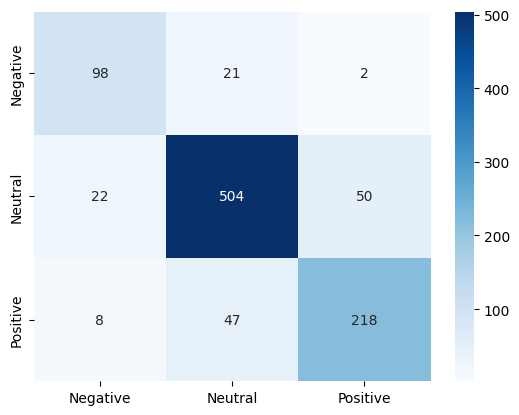

F1-score: 0.8227146559557189


In [19]:
trainer.model.config.id2label = {0: "negative", 1: "neutral", 2: "positive"}
trainer.model.config.label2id = {"negative": 0, "neutral": 1, "positive": 2} # shouldve done before
sentiment_model = pipeline(
    "text-classification",
    model=trainer.model,
    tokenizer=tokenizer
)

ft_res = sentiment_model(x_test.to_list())
ft_pred = pd.Series([res['label'] for res in ft_res]).map(target_map)

print(classification_report(y_test,ft_pred))
cm_bert = confusion_matrix(y_test,ft_pred)
sns.heatmap(cm_bert,cmap='Blues',annot=True,fmt='d',
            xticklabels=labels,yticklabels=labels)
plt.show()
print(f"F1-score: {f1_score(y_test,ft_pred,average='macro')}")

**Result:** macro F1 = **0.823**, which did **not** beat zero-shot (0.863). Precision and recall are more balanced but the overall score is lower. Possible reasons (untested hypotheses):
1. FinBERT already saw this data, so there was little left to learn.
2. The label order mismatch made the starting point worse.
3. Default settings, no validation, no early stopping.
4. One run, one seed.
To test: pass `id2label`/`label2id` into `from_pretrained`, evaluate each epoch, try lr 2e-5, repeat with a few seeds.

              precision    recall  f1-score   support

           0       0.75      1.00      0.86         3
           1       0.67      0.67      0.67         3
           2       1.00      0.75      0.86         4

    accuracy                           0.80        10
   macro avg       0.81      0.81      0.79        10
weighted avg       0.82      0.80      0.80        10



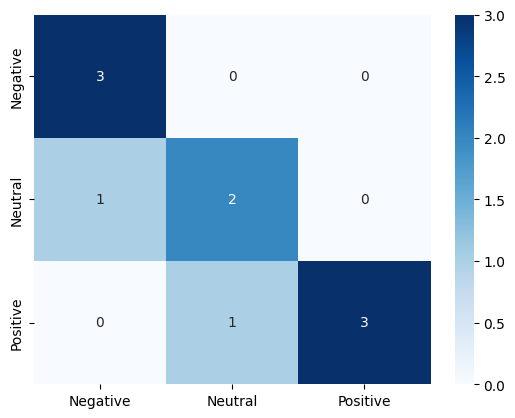

F1-score: 0.7936507936507936


In [20]:
ft_new_res = sentiment_model(latest_news.to_list())
ft_new_pred = pd.Series([res['label'] for res in ft_new_res]).map(target_map)

print(classification_report(sentiments,ft_new_pred))
cm_bert = confusion_matrix(sentiments,ft_new_pred)
sns.heatmap(cm_bert,cmap='Blues',annot=True,fmt='d',
            xticklabels=labels,yticklabels=labels)
plt.show()
print(f"F1-score: {f1_score(sentiments,ft_new_pred,average='macro')}")

**Result:** macro F1 = **0.794** (accuracy 0.80), against 0.785 for zero-shot FinBERT and 0.529 for the baseline, so **26.5 points above the baseline**.
- Negative: recall 1.00, precision 0.75. Neutral: precision and recall both 0.67. Positive: precision 1.00, recall 0.75 (3 of 4 found).
- Fine-tuned and zero-shot FinBERT have the same accuracy (0.80), and the F1 gap is under 1 point. With 10 headlines this is a **tie**, not a win.
- The fine-tuned model drops only 3.7 points from its test score (0.831), against 7.8 for zero-shot and 18.0 for the baseline. With 10 headlines, don't read much into that.

## Comparison
Same two test sets, same metrics. **Inference time** is wall-clock time to predict all 970 test sentences, so it depends on hardware. Note the device (CPU/GPU) when quoting it.

| Model | Test Macro F1 | Indian Headlines Macro F1 | Needs Training? |
|---|---|---|---|
| TF-IDF + LR | 0.709 | 0.529 | Yes |
| FinBERT (HF pipeline) | 0.863 | 0.785 | No |
| FinBERT (fine-tuned) | 0.823 | 0.794 | Yes (~18 min) |


## Insights
| Question | Answer |
|---|---|
| Best test macro F1 | FinBERT zero-shot, 0.863 |
| Best on Indian headlines | FinBERT fine-tunes, 0.794 (only 10 headlines) |
| Did fine-tuning help? | No, 0.823 vs 0.863 |


**Conclusion:** a pretrained financial transformer clearly beats TF-IDF with zero training and transfers better to Indian text. Fine-tuning on a small dataset did not help in this run.

**Limits:** only 10 Indian headlines labelled by one person, FinBERT has probably seen the test data, every model was run once, and times depend on hardware.